In [ ]:
!pip install datasets timm torch torchvision pillow numpy

Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00003.parquet:   0%|          | 0.00/461M [00:00<?, ?B/s]

data/train-00001-of-00003.parquet:   0%|          | 0.00/461M [00:00<?, ?B/s]

data/train-00002-of-00003.parquet:   0%|          | 0.00/459M [00:00<?, ?B/s]

... (4 outputs left out)

Generating test split:   0%|          | 0/12869 [00:00<?, ? examples/s]

Training samples: 69853
Validation samples: 12708
Testing samples: 12869
Building dynamic vocabulary from the training dataset...
Total Unique Characters (including blank): 109
Saved vocabulary to ctc_vocab.json


model.safetensors:   0%|          | 0.00/46.8M [00:00<?, ?B/s]

Starting End-to-End Sequence Training for 15 Epochs...
Epoch [1/15], Step [100/2183], Loss: 3.2103
Epoch [1/15], Step [200/2183], Loss: 1.7571
Epoch [1/15], Step [300/2183], Loss: 1.1586
Epoch [1/15], Step [400/2183], Loss: 0.8934
Epoch [1/15], Step [500/2183], Loss: 1.0832
Epoch [1/15], Step [600/2183], Loss: 0.9049
Epoch [1/15], Step [700/2183], Loss: 0.5131
Epoch [1/15], Step [800/2183], Loss: 0.9993
Epoch [1/15], Step [900/2183], Loss: 0.8018
Epoch [1/15], Step [1000/2183], Loss: 0.7596
Epoch [1/15], Step [1100/2183], Loss: 0.9597
Epoch [1/15], Step [1200/2183], Loss: 0.5865
Epoch [1/15], Step [1300/2183], Loss: 0.6620
Epoch [1/15], Step [1400/2183], Loss: 0.4895
Epoch [1/15], Step [1500/2183], Loss: 0.4215
Epoch [1/15], Step [1600/2183], Loss: 0.2706
Epoch [1/15], Step [1700/2183], Loss: 0.3320
Epoch [1/15], Step [1800/2183], Loss: 0.3944
Epoch [1/15], Step [1900/2183], Loss: 0.2835
Epoch [1/15], Step [2000/2183], Loss: 0.4112
Epoch [1/15], Step [2100/2183], Loss: 0.3111
==== Epoc

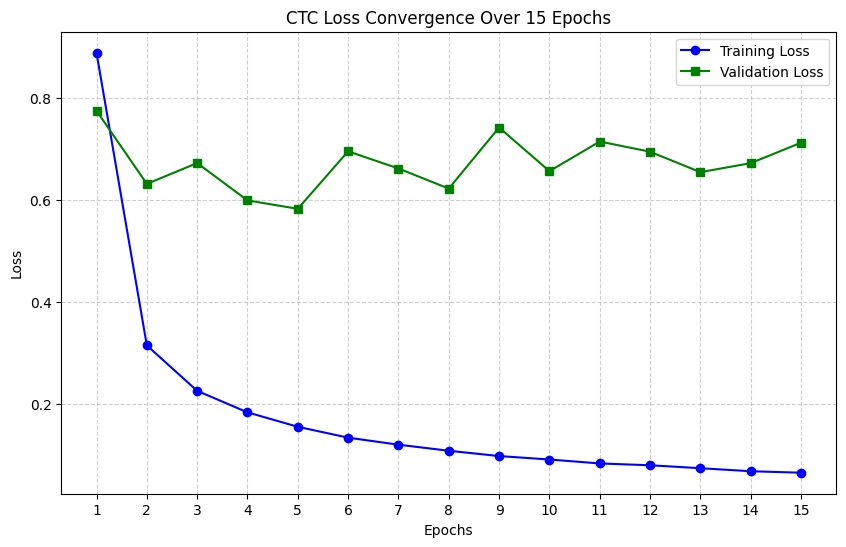

Graph saved as 'loss_convergence_graph.png'


In [1]:
import torch
import torch.nn as nn
import timm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
import json
import matplotlib.pyplot as plt  # Added for metric plotting
import os

# --- 1. DEVICE & DATASET LOADING ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

print("Downloading dataset from Hugging Face...")
hf_dataset = load_dataset("c3rl/IIIT-INDIC-HW-WORDS-Hindi")

train_data = hf_dataset['train']
val_data = hf_dataset['validation']
test_data = hf_dataset['test']

print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(val_data)}")
print(f"Testing samples: {len(test_data)}")

# --- 2. DYNAMIC VOCABULARY BUILDER ---
print("Building dynamic vocabulary from the training dataset...")
unique_chars = set()
for item in train_data:
    text = item['text']
    if text:
        unique_chars.update(list(text))

vocab = ["<BLANK>"] + sorted(list(unique_chars))
char_to_idx = {char: idx for idx, char in enumerate(vocab)}
idx_to_char = {idx: char for idx, char in enumerate(vocab)}
num_classes = len(vocab)
print(f"Total Unique Characters (including blank): {num_classes}")

with open('ctc_vocab.json', 'w', encoding='utf-8') as f:
    json.dump(idx_to_char, f, ensure_ascii=False, indent=4)
print("Saved vocabulary to ctc_vocab.json")

# --- 3. CUSTOM PYTORCH DATASET ---
class HFWordDataset(Dataset):
    def __init__(self, hf_split, transform=None):
        self.hf_split = hf_split
        self.transform = transform

    def __len__(self):
        return len(self.hf_split)

    def __getitem__(self, idx):
        item = self.hf_split[idx]
        image = item['image'].convert('RGB')
        text = item['text']

        if self.transform:
            image = self.transform(image)

        target = [char_to_idx[c] for c in text if c in char_to_idx]
        target_length = len(target)

        return image, target, target_length

transform = transforms.Compose([
    transforms.Resize((64, 384)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = HFWordDataset(train_data, transform=transform)
val_dataset = HFWordDataset(val_data, transform=transform)
test_dataset = HFWordDataset(test_data, transform=transform)

# --- 4. THE CTC COLLATE FUNCTION ---
def ctc_collate_fn(batch):
    images, targets, target_lengths = [], [], []
    for img, tgt, tgt_len in batch:
        images.append(img)
        targets.extend(tgt)
        target_lengths.append(tgt_len)

    images = torch.stack(images)
    targets = torch.tensor(targets, dtype=torch.long)
    target_lengths = torch.tensor(target_lengths, dtype=torch.long)

    return images, targets, target_lengths

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=ctc_collate_fn)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, collate_fn=ctc_collate_fn)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=ctc_collate_fn)

# --- 5. THE HYBRID SEQUENCE ARCHITECTURE ---
class HybridCTCModel(nn.Module):
    def __init__(self, num_classes):
        super(HybridCTCModel, self).__init__()

        resnet = timm.create_model('resnet18', pretrained=True)
        self.cnn = nn.Sequential(
            resnet.conv1, resnet.bn1, resnet.act1, resnet.maxpool,
            resnet.layer1,
            resnet.layer2,
            resnet.layer3
        )

        self.sequence_builder = nn.Conv2d(256, 256, kernel_size=(4, 1))

        self.transformer_layer = nn.TransformerEncoderLayer(d_model=256, nhead=8, batch_first=True)
        self.transformer = nn.TransformerEncoder(self.transformer_layer, num_layers=2)

        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.cnn(x)                # [B, 256, 4, 24]
        x = self.sequence_builder(x)   # [B, 256, 1, 24]
        x = x.squeeze(2).permute(0, 2, 1) # [B, 24, 256]
        x = self.transformer(x)
        x = self.fc(x)                 # [B, 24, Num_Classes]

        return x.log_softmax(2).permute(1, 0, 2)

# --- 6. INITIALIZE TRAINING ---
model = HybridCTCModel(num_classes).to(device)
criterion = nn.CTCLoss(blank=0, zero_infinity=True)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0003)

# --- 7. METRICS TRACKING SETUP ---
epochs = 15
seq_length = 24

# Lists to store metrics for plotting
history_train_loss = []
history_val_loss = []
current_epoch = 0 # To track where we are if interrupted

# --- 8. TRAINING LOOP WITH INTERRUPTION HANDLING ---
print(f"Starting End-to-End Sequence Training for {epochs} Epochs...")

try:
    for epoch in range(epochs):
        current_epoch = epoch + 1
        model.train()
        running_loss = 0.0

        for i, (images, targets, target_lengths) in enumerate(train_loader):
            images = images.to(device)
            targets = targets.to(device)

            batch_size = images.size(0)

            input_lengths = torch.full(size=(batch_size,), fill_value=seq_length, dtype=torch.long).to(device)

            optimizer.zero_grad()
            preds = model(images)

            loss = criterion(preds, targets, input_lengths, target_lengths)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()

            running_loss += loss.item()

            if (i + 1) % 100 == 0:
                print(f"Epoch [{current_epoch}/{epochs}], Step [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}")

        avg_train_loss = running_loss / len(train_loader)
        history_train_loss.append(avg_train_loss)

        # --- VALIDATION PHASE ---
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, targets, target_lengths in val_loader:
                images = images.to(device)
                targets = targets.to(device)
                batch_size = images.size(0)
                input_lengths = torch.full(size=(batch_size,), fill_value=seq_length, dtype=torch.long).to(device)

                preds = model(images)
                loss = criterion(preds, targets, input_lengths, target_lengths)
                val_loss += loss.item()

        avg_val_loss = val_loss / len(val_loader)
        history_val_loss.append(avg_val_loss)

        print(f"==== Epoch [{current_epoch}/{epochs}] Summary ====")
        print(f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
        print("====================================\n")

        # --- SAVE CHECKPOINT EVERY EPOCH ---
        torch.save({
            'epoch': current_epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'history_train_loss': history_train_loss,
            'history_val_loss': history_val_loss
        }, 'hybrid_ctc_model_checkpoint.pth')
        print(f"✅ Checkpoint saved for Epoch {current_epoch}.")

    # --- 9. SAVE FINAL MODEL ---
    torch.save(model.state_dict(), 'hybrid_ctc_model.pth')
    print("Training Complete! Saved final hybrid_ctc_model.pth")

except KeyboardInterrupt:
    print("\n⚠️ Training interrupted manually! Packaging emergency checkpoint...")
    torch.save({
        'epoch': current_epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'history_train_loss': history_train_loss,
        'history_val_loss': history_val_loss
    }, 'interrupted_checkpoint.pth')
    print("✅ Emergency checkpoint successfully saved as 'interrupted_checkpoint.pth'")

except Exception as e:
    print(f"\n❌ Unexpected error occurred: {e}. Packaging emergency checkpoint...")
    torch.save({
        'epoch': current_epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'history_train_loss': history_train_loss,
        'history_val_loss': history_val_loss
    }, 'error_checkpoint.pth')
    print("✅ Emergency error checkpoint successfully saved as 'error_checkpoint.pth'")

# --- 10. PLOT AND SAVE METRICS GRAPH ---
if len(history_train_loss) > 0:
    print("Generating convergence graph...")
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(history_train_loss) + 1), history_train_loss, label='Training Loss', marker='o', color='blue')
    plt.plot(range(1, len(history_val_loss) + 1), history_val_loss, label='Validation Loss', marker='s', color='green')

    plt.title(f'CTC Loss Convergence Over {len(history_train_loss)} Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.xticks(range(1, len(history_train_loss) + 1))
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

    plt.savefig('loss_convergence_graph.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("Graph saved as 'loss_convergence_graph.png'")
else:
    print("Training was interrupted before completing the first epoch. No graph to display.")